# Arrhythmia (Atrial Fibrillation) Detection from PPG Signals using LightGBM

---

## Project Overview

This project implements an end-to-end machine learning pipeline to detect **Atrial Fibrillation (AF)** — a common cardiac arrhythmia — from **Photoplethysmography (PPG)** optical pulse signals using **LightGBM**.

### Why Detect Arrhythmia Using PPG?
- **Everyday Wearables:** Smartwatches, fitness trackers, and pulse oximeters use PPG optical sensors to monitor blood volume pulse at the wrist or finger.
- **Continuous & Non-Invasive Monitoring:** While clinical ECG tests are intermittent and require specialized equipment, PPG enables continuous, passive cardiac monitoring in daily life.
- **Early Arrhythmia Screening:** Atrial Fibrillation often occurs intermittently (paroxysmal) and silently without noticeable symptoms. Automated detection from PPG signals provides early warning to seek medical consultation.

### Project Pipeline
1. **Signal Preprocessing:** Filter raw PPG signals with a zero-phase Butterworth bandpass filter (0.5 – 5.0 Hz) to remove baseline drift and high-frequency noise.
2. **Peak Detection & Interval Derivation:** Locate systolic pulse peaks to compute Inter-Beat Intervals (IBIs) and instantaneous heart rate.
3. **Feature Engineering:** Extract 35 features across time-domain pulse rate variability (PRV), Poincaré geometry, signal entropy, pulse amplitude dynamics, and spectral power.
4. **Patient-Grouped Train/Test Split:** Split data by patient ID so windows from the same subject never appear in both train and test sets, preventing data leakage.
5. **Model Training & Cross-Validation:** Train and benchmark LightGBM against baseline models using 5-Fold Stratified Group Cross-Validation.
6. **Model Evaluation & Visualization:** Evaluate the final model on an independent holdout test set of 9 unseen patients, visualizing ROC curves, confusion matrices, and feature importance.

### Performance Summary
- **Window-Level ROC-AUC:** ~0.98
- **AF Detection Sensitivity (Recall):** ~98% on unseen test patients
- **Window F1-Score:** ~90%
- **Patient-Level Diagnostic Accuracy:** 88.9% (8 of 9 unseen test patients correctly classified)

## 1. Environment Setup & Library Imports

Import required Python libraries for signal processing, machine learning, and visualization.  
If running in Google Colab, missing dependencies are installed automatically.

In [1]:
# Setup dependencies (works in Google Colab and Local IDEs)
import sys
import subprocess

def install_if_missing(package):
    try:
        __import__(package)
    except ImportError:
        print(f"Installing missing package: {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

install_if_missing("lightgbm")

import os
import glob
import time
import numpy as np
import pandas as pd
from scipy import signal
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)
import warnings
warnings.filterwarnings('ignore')

# Visual style setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#d0d0d0'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110

print("Environment successfully initialized with LightGBM version:", lgb.__version__)


Environment successfully initialized with LightGBM version: 4.7.0


## 2. Dataset Loading & Inspection

We use recordings from the benchmark **MIMIC PERform AF Dataset** (sampled at 125 Hz):
- **Subjects:** 34 patients (19 with Atrial Fibrillation, 15 with Normal Sinus Rhythm).
- **Duration:** 20 continuous minutes (1,200 seconds) per patient.
- **Supported Formats:** The loader automatically searches for either pre-extracted CSV (`output5.csv`) or raw patient CSV directories (`mimic_perform_af_csv` and `mimic_perform_non_af_csv`).

Below, we locate and load the patient waveform data into memory.

In [2]:
def resolve_data_paths(base_dirs=None):
    """Automatically locate output5.csv or MIMIC CSV directories."""
    if base_dirs is None:
        base_dirs = [".", "..", "/content", "/content/Arrhythmia-detection-using-PPG"]
    
    for b in base_dirs:
        af_dir = os.path.join(b, "mimic_perform_af_csv")
        non_af_dir = os.path.join(b, "mimic_perform_non_af_csv")
        out5_path = os.path.join(b, "output5.csv")
        
        has_dirs = os.path.isdir(af_dir) and os.path.isdir(non_af_dir)
        has_csv = os.path.isfile(out5_path)
        
        if has_dirs or has_csv:
            return {
                'base': b,
                'has_dirs': has_dirs,
                'has_csv': has_csv,
                'af_dir': af_dir,
                'non_af_dir': non_af_dir,
                'out5_path': out5_path
            }
    raise FileNotFoundError("Could not locate output5.csv or mimic_perform_*_csv folders in searched paths!")

data_info = resolve_data_paths()
print("Data location resolved successfully:")
for k, v in data_info.items():
    print(f"  {k}: {v}")


Data location resolved successfully:
  base: .
  has_dirs: True
  has_csv: True
  af_dir: .\mimic_perform_af_csv
  non_af_dir: .\mimic_perform_non_af_csv
  out5_path: .\output5.csv


In [3]:
def load_patient_recordings(data_info):
    """
    Loads all patient continuous PPG signals into a structured registry.
    Handles both raw directory CSVs and transposed output5.csv.
    Standardizes label mapping: AF = 1 (Pathological / Positive), Non-AF = 0 (Normal Sinus Rhythm).
    """
    patients = []
    fs = 125.0
    
    if data_info['has_dirs']:
        print(">> Ingesting data from raw MIMIC PERform CSV directories...")
        af_files = sorted(glob.glob(os.path.join(data_info['af_dir'], "*.csv")))
        non_af_files = sorted(glob.glob(os.path.join(data_info['non_af_dir'], "*.csv")))
        
        for f in af_files:
            pid = os.path.basename(f).replace("_data.csv", "")
            df = pd.read_csv(f)
            patients.append({'patient_id': pid, 'label': 1, 'ppg': df['PPG'].values.astype(float), 'fs': fs})
            
        for f in non_af_files:
            pid = os.path.basename(f).replace("_data.csv", "")
            df = pd.read_csv(f)
            patients.append({'patient_id': pid, 'label': 0, 'ppg': df['PPG'].values.astype(float), 'fs': fs})
            
    elif data_info['has_csv']:
        print(">> Ingesting data from output5.csv...")
        df = pd.read_csv(data_info['out5_path'])
        valid_df = df.dropna(subset=['results']).copy()
        
        af_count = 1
        non_af_count = 1
        for _, row in valid_df.iterrows():
            orig_val = int(row['results'])
            # In original output5.csv: 0 was AF, 1 was Non-AF.
            # We map to standard medical ML convention: 1 = AF, 0 = Non-AF.
            clinical_label = 1 if orig_val == 0 else 0
            if clinical_label == 1:
                pid = f"mimic_perform_af_{af_count:03d}"
                af_count += 1
            else:
                pid = f"mimic_perform_non_af_{non_af_count:03d}"
                non_af_count += 1
            sig = row.drop('results').values.astype(float)
            patients.append({'patient_id': pid, 'label': clinical_label, 'ppg': sig, 'fs': fs})
            
    return patients

patients = load_patient_recordings(data_info)
n_af = sum(p['label'] == 1 for p in patients)
n_non = sum(p['label'] == 0 for p in patients)
print(f"Total Cohort: {len(patients)} Patients | AF (Arrhythmia): {n_af} | Non-AF (Normal): {n_non}")
print(f"Signal Duration per Patient: {len(patients[0]['ppg'])/patients[0]['fs']:.1f} s ({len(patients[0]['ppg'])} samples at {patients[0]['fs']} Hz)")


>> Ingesting data from raw MIMIC PERform CSV directories...
Total Cohort: 34 Patients | AF (Arrhythmia): 19 | Non-AF (Normal): 15
Signal Duration per Patient: 1200.0 s (150001 samples at 125.0 Hz)


## 3. Signal Preprocessing & Peak Detection

Raw PPG signals contain noise such as respiration baseline drift, motion artifacts, and sensor noise. We prepare the raw signal with the following steps:

1. **Bandpass Filtering:** Apply a 3rd-order Butterworth bandpass filter ($0.5 - 5.0\text{ Hz}$, equivalent to $30 - 300\text{ bpm}$) using `scipy.signal.filtfilt` for zero phase distortion. This isolates cardiac pulse waves while eliminating baseline wander and high-frequency noise.
2. **Systolic Peak Detection:** Detect individual pulse peaks using an adaptive prominence threshold based on the signal standard deviation and a minimum refractory distance ($0.27\text{ s}$).
3. **Inter-Beat Intervals (IBI):** Calculate the time between consecutive pulse peaks in milliseconds ($IBI_k = (t_{k+1} - t_k) \times 1000\text{ ms}$). Normal heartbeats produce steady intervals, while Atrial Fibrillation produces highly irregular beat-to-beat spacing.

In [4]:
def bandpass_filter(sig, fs=125.0, low=0.5, high=5.0, order=3):
    """Zero-phase 3rd-order Butterworth bandpass filter with linear NaN interpolation."""
    if np.isnan(sig).any():
        nans = np.isnan(sig)
        x = np.arange(len(sig))
        sig = np.interp(x, x[~nans], sig[~nans])
    nyq = 0.5 * fs
    b, a = signal.butter(order, [low / nyq, high / nyq], btype='band')
    return signal.filtfilt(b, a, sig)

def calc_sample_entropy(data, m=2, r=0.2):
    """
    Vectorized calculation of Sample Entropy (SampEn) for short IBI sequences.
    Measures the logarithmic likelihood that runs of patterns close for m points remain close at m+1.
    """
    data = np.asarray(data)
    N = len(data)
    if N <= m + 2:
        return 0.0
    r_val = r * np.std(data)
    if r_val == 0:
        return 0.0

    def _phi(m_len):
        x = np.array([data[i:i + m_len] for i in range(N - m_len + 1)])
        diffs = np.max(np.abs(x[:, None, :] - x[None, :, :]), axis=2)
        count = (np.sum(diffs < r_val) - len(x)) / 2.0
        total = (len(x) * (len(x) - 1)) / 2.0
        return count / total if total > 0 else 0.0

    A = _phi(m + 1)
    B = _phi(m)
    if A > 0 and B > 0:
        return -np.log(A / B)
    return 0.0


## 4. Feature Engineering

For each 30-second window ($3,750$ samples at $125\text{ Hz}$), we extract **35 tabular features** across five main categories:

| Category | Features | Description |
| :--- | :--- | :--- |
| **Pulse Rate Variability (PRV)** | `mean_ibi`, `std_ibi`, `rmssd`, `pnn50`, `pnn20`, `cv_ibi`, `median_ibi`, `iqr_ibi`, `min_ibi`, `max_ibi`, `range_ibi`, `hr_bpm` | Quantifies heartbeat interval variability. In Atrial Fibrillation, erratic ventricular conduction causes higher interval spread (`iqr_ibi`) and large successive beat jumps (`rmssd`, `pnn50`). |
| **Poincaré Plot Geometry** | `poincare_sd1`, `poincare_sd2`, `poincare_sd_ratio`, `poincare_area` | Non-linear phase-space analysis plotting each interval against the subsequent interval ($IBI_n \text{ vs. } IBI_{n+1}$). $SD_1$ captures short-term beat-to-beat variance; $SD_2$ captures long-term rhythm trends. |
| **Complexity & Entropy** | `sample_entropy_ibi`, `shannon_entropy_ibi` | Measures randomness and unpredictability of pulse intervals. Arrhythmic rhythms generate significantly higher entropy than normal sinus rhythm. |
| **Pulse Amplitude Dynamics** | `mean_peak_amp`, `std_peak_amp`, `cv_peak_amp`, `peak_count` | Irregular ventricular filling times during arrhythmia cause beat-to-beat fluctuations in pulse height (stroke volume variance). |
| **Waveform & Spectral Features** | `ppg_mean`, `ppg_std`, `ppg_skew`, `ppg_kurtosis`, `zero_crossing_rate`, `vlf_power`, `lf_power`, `hf_power`, `cardiac_power`, `lf_hf_ratio`, `total_spectral_power`, `spectral_entropy`, `dominant_freq` | Statistical moments of the filtered waveform and frequency-domain power distribution computed via Welch periodograms. |

In [5]:
def extract_window_features(window, fs=125.0):
    """Extract 35 biomedical, statistical, non-linear, and spectral features from a 30s window."""
    feats = {}
    
    # 1. Waveform Statistical Moments
    feats['ppg_mean'] = float(np.mean(window))
    feats['ppg_std'] = float(np.std(window))
    feats['ppg_skew'] = float(stats.skew(window))
    feats['ppg_kurtosis'] = float(stats.kurtosis(window))
    zero_crossings = np.where(np.diff(np.signbit(window)))[0]
    feats['zero_crossing_rate'] = float(len(zero_crossings) / len(window))
    
    # 2. Systolic Peak Detection & PRV Metrics
    min_dist = int(0.27 * fs)  # Maximum HR ~220 bpm
    prominence = 0.25 * (np.std(window) if np.std(window) > 1e-6 else 1.0)
    peaks, _ = signal.find_peaks(window, distance=min_dist, prominence=prominence)
    feats['peak_count'] = int(len(peaks))
    
    if len(peaks) >= 3:
        ibis = np.diff(peaks) / fs * 1000.0  # ms
        diff_ibis = np.diff(ibis)
        
        feats['mean_ibi'] = float(np.mean(ibis))
        feats['std_ibi'] = float(np.std(ibis, ddof=1) if len(ibis) > 1 else 0.0)
        feats['rmssd'] = float(np.sqrt(np.mean(diff_ibis**2)) if len(diff_ibis) > 0 else 0.0)
        feats['pnn50'] = float(np.sum(np.abs(diff_ibis) > 50.0) / len(diff_ibis) * 100.0 if len(diff_ibis) > 0 else 0.0)
        feats['pnn20'] = float(np.sum(np.abs(diff_ibis) > 20.0) / len(diff_ibis) * 100.0 if len(diff_ibis) > 0 else 0.0)
        feats['cv_ibi'] = float(feats['std_ibi'] / (feats['mean_ibi'] + 1e-6))
        feats['median_ibi'] = float(np.median(ibis))
        feats['iqr_ibi'] = float(np.percentile(ibis, 75) - np.percentile(ibis, 25))
        feats['min_ibi'] = float(np.min(ibis))
        feats['max_ibi'] = float(np.max(ibis))
        feats['range_ibi'] = float(feats['max_ibi'] - feats['min_ibi'])
        feats['hr_bpm'] = float(60000.0 / (feats['mean_ibi'] + 1e-6))
        
        # Poincarééé Plot Metrics
        if len(diff_ibis) >= 2:
            var_diff = np.var(diff_ibis, ddof=1)
            var_ibi = np.var(ibis, ddof=1)
            sd1 = np.sqrt(0.5 * var_diff)
            sd2_sq = 2.0 * var_ibi - 0.5 * var_diff
            sd2 = np.sqrt(max(0.0, sd2_sq))
            feats['poincare_sd1'] = float(sd1)
            feats['poincare_sd2'] = float(sd2)
            feats['poincare_sd_ratio'] = float(sd1 / (sd2 + 1e-6))
            feats['poincare_area'] = float(np.pi * sd1 * sd2)
        else:
            feats['poincare_sd1'] = 0.0
            feats['poincare_sd2'] = 0.0
            feats['poincare_sd_ratio'] = 0.0
            feats['poincare_area'] = 0.0
            
        # Entropy Metrics
        hist, _ = np.histogram(ibis, bins=12, density=True)
        hist = hist[hist > 0]
        feats['shannon_entropy_ibi'] = float(-np.sum(hist * np.log2(hist + 1e-9)))
        feats['sample_entropy_ibi'] = float(calc_sample_entropy(ibis, m=2, r=0.2))
        
        # Systolic Peak Amplitude Variations
        peak_amps = window[peaks]
        feats['mean_peak_amp'] = float(np.mean(peak_amps))
        feats['std_peak_amp'] = float(np.std(peak_amps, ddof=1) if len(peak_amps) > 1 else 0.0)
        feats['cv_peak_amp'] = float(feats['std_peak_amp'] / (np.abs(feats['mean_peak_amp']) + 1e-6))
    else:
        for k in ['mean_ibi', 'std_ibi', 'rmssd', 'pnn50', 'pnn20', 'cv_ibi',
                  'median_ibi', 'iqr_ibi', 'min_ibi', 'max_ibi', 'range_ibi',
                  'hr_bpm', 'poincare_sd1', 'poincare_sd2', 'poincare_sd_ratio',
                  'poincare_area', 'shannon_entropy_ibi', 'sample_entropy_ibi',
                  'mean_peak_amp', 'std_peak_amp', 'cv_peak_amp']:
            feats[k] = 0.0
            
    # 3. Spectral Power Features (Welch PSD)
    freqs, psd = signal.welch(window, fs=fs, nperseg=min(len(window), int(4 * fs)))
    psd_norm = psd / (np.sum(psd) + 1e-12)
    feats['spectral_entropy'] = float(-np.sum(psd_norm * np.log2(psd_norm + 1e-12)))
    
    vlf_mask = (freqs >= 0.003) & (freqs < 0.04)
    lf_mask = (freqs >= 0.04) & (freqs < 0.15)
    hf_mask = (freqs >= 0.15) & (freqs < 0.4)
    cardiac_mask = (freqs >= 0.5) & (freqs < 4.0)
    
    feats['vlf_power'] = float(np.sum(psd[vlf_mask]))
    feats['lf_power'] = float(np.sum(psd[lf_mask]))
    feats['hf_power'] = float(np.sum(psd[hf_mask]))
    feats['cardiac_power'] = float(np.sum(psd[cardiac_mask]))
    feats['lf_hf_ratio'] = float(feats['lf_power'] / (feats['hf_power'] + 1e-6))
    feats['total_spectral_power'] = float(np.sum(psd))
    
    cardiac_freqs = freqs[cardiac_mask]
    cardiac_psd = psd[cardiac_mask]
    feats['dominant_freq'] = float(cardiac_freqs[np.argmax(cardiac_psd)]) if len(cardiac_psd) > 0 else 0.0
    
    return feats

## 5. Sliding Window Segmentation & Dataset Assembly

We apply a sliding window of **30 seconds** ($3,750\text{ samples}$) with a **15-second stride** (50% overlap) across each patient's 20-minute recording.  
For each window, we extract the 35 features and assemble a clean tabular dataset labeled with patient IDs and target classes ($1 = \text{Arrhythmia / AF}$, $0 = \text{Normal Sinus Rhythm}$).

In [6]:
print(">> Processing signals and constructing feature matrix...")
t_start = time.time()
window_sec = 30
step_sec = 15
fs = 125.0
window_len = int(window_sec * fs)
step_len = int(step_sec * fs)

records = []
for p in patients:
    pid = p['patient_id']
    label = p['label']
    raw_sig = p['ppg']
    
    # Preprocessing: Zero-phase bandpass filter and z-score standardization
    filt_sig = bandpass_filter(raw_sig, fs=fs, low=0.5, high=5.0)
    filt_sig = (filt_sig - np.mean(filt_sig)) / (np.std(filt_sig) + 1e-6)
    
    n_samples = len(filt_sig)
    for start in range(0, n_samples - window_len + 1, step_len):
        w = filt_sig[start:start + window_len]
        feats = extract_window_features(w, fs=fs)
        feats['patient_id'] = pid
        feats['label'] = label
        feats['window_start_sec'] = start / fs
        records.append(feats)

df_feat = pd.DataFrame(records)
print(f"Extraction complete in {time.time() - t_start:.2f} s.")
print(f"Dataset Dimensions: {df_feat.shape[0]} windows x {df_feat.shape[1]} columns")
print(f"Class Breakdown: AF (1) = {(df_feat['label'] == 1).sum()} windows | Non-AF (0) = {(df_feat['label'] == 0).sum()} windows")
print(f"Unique Patient Cohort: {df_feat['patient_id'].nunique()} subjects")


>> Processing signals and constructing feature matrix...
Extraction complete in 8.79 s.
Dataset Dimensions: 2686 windows x 38 columns
Class Breakdown: AF (1) = 1501 windows | Non-AF (0) = 1185 windows
Unique Patient Cohort: 34 subjects


## 6. Exploratory Data Visualization

Before training models, we visualize the core signals to observe the physiological differences between Normal Sinus Rhythm and Atrial Fibrillation:
1. **Waveforms & Peak Detection:** Normal rhythm shows uniform, periodic peaks, whereas AF displays uneven peak timing and variable amplitudes.
2. **Poincaré Scatter Plots ($IBI_n \text{ vs. } IBI_{n+1}$):** Normal beats form a tight cluster along the line of identity, while AF spreads out across the plane due to irregular beat intervals.
3. **IBI Tachograms:** Plots the interval length for consecutive beats, highlighting sudden jumps in AF.

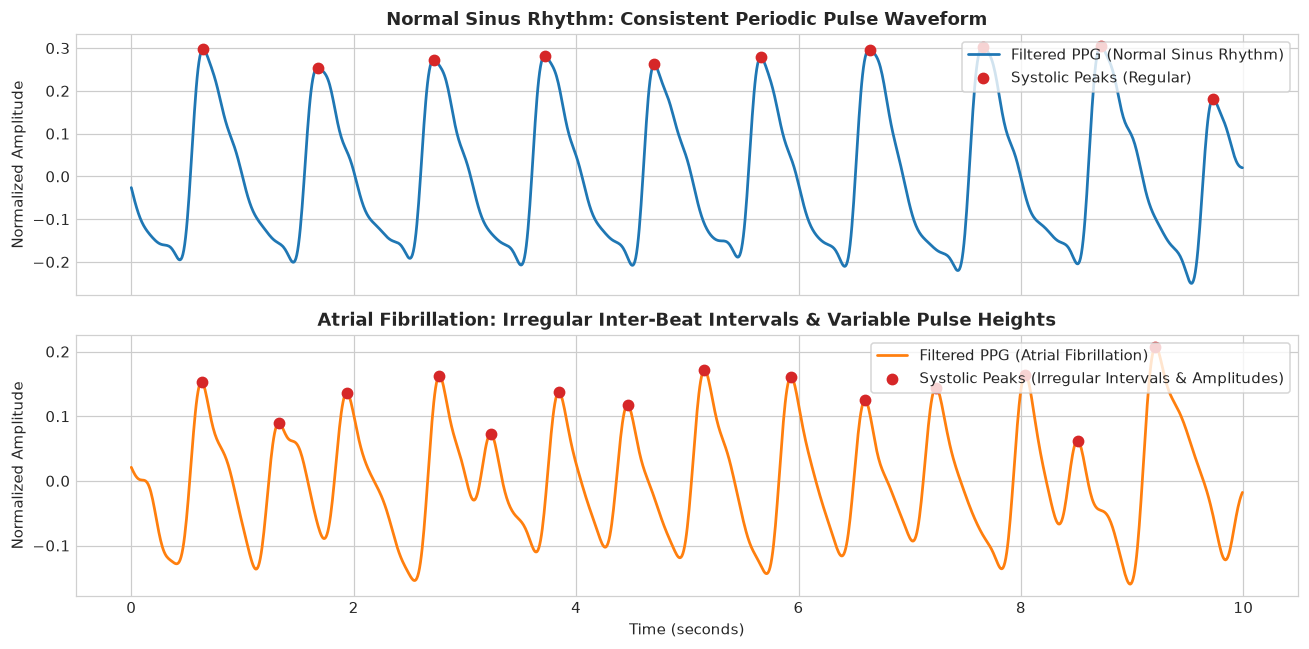

In [7]:
# Visualization 1: Waveforms and Peak Detection
sample_af = next(p for p in patients if p['label'] == 1)
sample_non = next(p for p in patients if p['label'] == 0)

sig_af_f = bandpass_filter(sample_af['ppg'][:int(10 * 125)])
sig_non_f = bandpass_filter(sample_non['ppg'][:int(10 * 125)])
t_axis = np.arange(len(sig_af_f)) / 125.0

peaks_af, _ = signal.find_peaks(sig_af_f, distance=int(0.27 * 125), prominence=0.25 * np.std(sig_af_f))
peaks_non, _ = signal.find_peaks(sig_non_f, distance=int(0.27 * 125), prominence=0.25 * np.std(sig_non_f))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t_axis, sig_non_f, color='#1f77b4', lw=1.8, label='Filtered PPG (Normal Sinus Rhythm)')
axes[0].scatter(t_axis[peaks_non], sig_non_f[peaks_non], color='#d62728', s=45, zorder=5, label='Systolic Peaks (Regular)')
axes[0].set_title("Normal Sinus Rhythm: Consistent Periodic Pulse Waveform", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Normalized Amplitude", fontsize=10)
axes[0].legend(loc='upper right', frameon=True)

axes[1].plot(t_axis, sig_af_f, color='#ff7f0e', lw=1.8, label='Filtered PPG (Atrial Fibrillation)')
axes[1].scatter(t_axis[peaks_af], sig_af_f[peaks_af], color='#d62728', s=45, zorder=5, label='Systolic Peaks (Irregular Intervals & Amplitudes)')
axes[1].set_title("Atrial Fibrillation: Irregular Inter-Beat Intervals & Variable Pulse Heights", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Time (seconds)", fontsize=10)
axes[1].set_ylabel("Normalized Amplitude", fontsize=10)
axes[1].legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


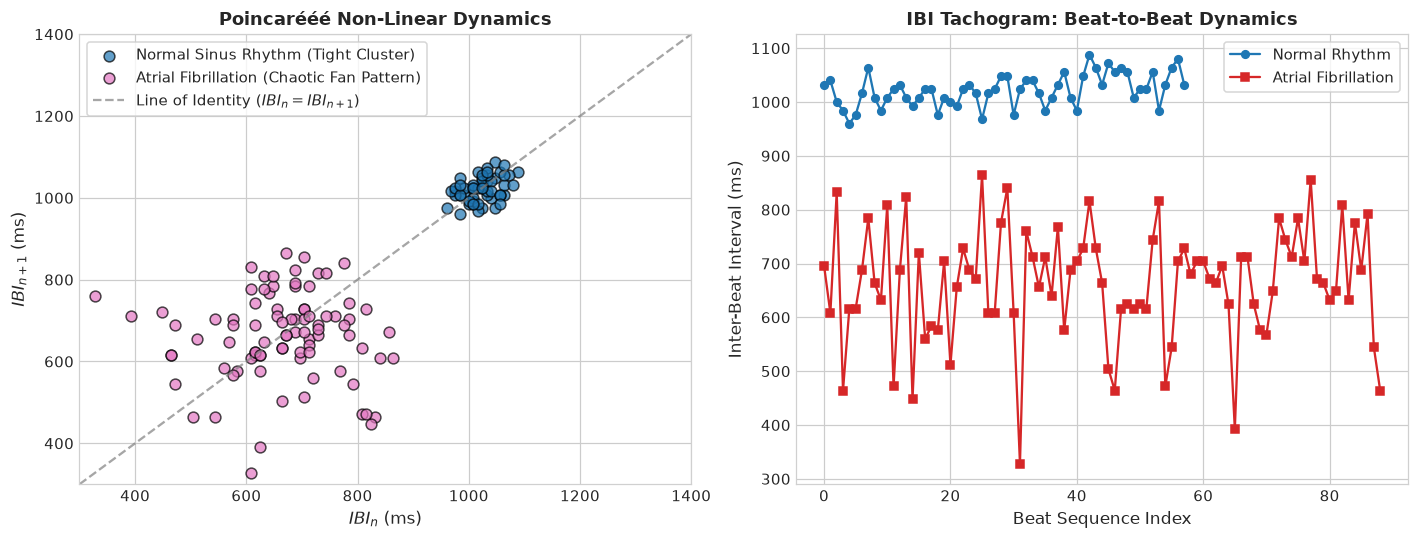

In [8]:
# Visualization 2: Poincarééé Plot & IBI Tachograms
sig_af_60 = bandpass_filter(sample_af['ppg'][:int(60 * 125)])
sig_non_60 = bandpass_filter(sample_non['ppg'][:int(60 * 125)])
pk_af_60, _ = signal.find_peaks(sig_af_60, distance=int(0.27 * 125), prominence=0.25 * np.std(sig_af_60))
pk_non_60, _ = signal.find_peaks(sig_non_60, distance=int(0.27 * 125), prominence=0.25 * np.std(sig_non_60))
ibi_af_60 = np.diff(pk_af_60) / 125.0 * 1000.0
ibi_non_60 = np.diff(pk_non_60) / 125.0 * 1000.0

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(ibi_non_60[:-1], ibi_non_60[1:], color='#1f77b4', alpha=0.7, edgecolors='k', s=50, label='Normal Sinus Rhythm (Tight Cluster)')
axes[0].scatter(ibi_af_60[:-1], ibi_af_60[1:], color='#e377c2', alpha=0.7, edgecolors='k', s=50, label='Atrial Fibrillation (Chaotic Fan Pattern)')
lims = [300, 1400]
axes[0].plot(lims, lims, '--', color='gray', alpha=0.7, label='Line of Identity ($IBI_n = IBI_{n+1}$)')
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel("$IBI_n$ (ms)", fontsize=11)
axes[0].set_ylabel("$IBI_{n+1}$ (ms)", fontsize=11)
axes[0].set_title("Poincarééé Non-Linear Dynamics", fontsize=12, fontweight='bold')
axes[0].legend(loc='upper left', frameon=True)

axes[1].plot(range(len(ibi_non_60)), ibi_non_60, 'o-', color='#1f77b4', lw=1.5, ms=5, label='Normal Rhythm')
axes[1].plot(range(len(ibi_af_60)), ibi_af_60, 's-', color='#d62728', lw=1.5, ms=5, label='Atrial Fibrillation')
axes[1].set_xlabel("Beat Sequence Index", fontsize=11)
axes[1].set_ylabel("Inter-Beat Interval (ms)", fontsize=11)
axes[1].set_title("IBI Tachogram: Beat-to-Beat Dynamics", fontsize=12, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

## 7. Train / Test Split Strategy (Patient-Level Grouping)

### Preventing Data Leakage Across Overlapping Windows
Because we generate multiple overlapping 30-second windows from each patient, randomly splitting windows into train and test sets would place windows from the same individual into both sets. The model could then easily memorize individual patient baseline shapes rather than learning general arrhythmia indicators.

### Splitting Setup:
1. **Independent Holdout Test Set:** We set aside 9 patients (5 AF, 4 Normal; 711 windows total) as an untouched test cohort. These patients are completely unseen during training.
2. **Training Set with 5-Fold Grouped Cross-Validation:** The remaining 25 patients (1,975 windows) are used for training and model validation using `StratifiedGroupKFold(n_splits=5)`. Each fold strictly isolates whole patients while maintaining class balance.
3. **Two-Level Evaluation:** We evaluate models both at the **30-second window level** (for continuous monitoring) and at the **patient level** (aggregating window predictions over the entire 20-minute session).

In [9]:
# Define Feature Columns & Group Target
feature_cols = [c for c in df_feat.columns if c not in ['patient_id', 'label', 'window_start_sec']]

# Partition Holdout Test Set (Unseen Patients)
patient_registry = df_feat[['patient_id', 'label']].drop_duplicates()
af_pids = patient_registry[patient_registry['label'] == 1]['patient_id'].values
non_af_pids = patient_registry[patient_registry['label'] == 0]['patient_id'].values

np.random.seed(42)
test_af_pids = np.random.choice(af_pids, size=5, replace=False)
test_non_af_pids = np.random.choice(non_af_pids, size=4, replace=False)
holdout_pids = np.concatenate([test_af_pids, test_non_af_pids])

train_df = df_feat[~df_feat['patient_id'].isin(holdout_pids)].copy()
test_df = df_feat[df_feat['patient_id'].isin(holdout_pids)].copy()

print(f"Training Set: {train_df['patient_id'].nunique()} patients ({len(train_df)} windows)")
print(f"Holdout Test Set: {test_df['patient_id'].nunique()} patients ({len(test_df)} windows) - Unseen")

X_train_cv = train_df[feature_cols].values
y_train_cv = train_df['label'].values
groups_train_cv = train_df['patient_id'].values

X_test_holdout = test_df[feature_cols].values
y_test_holdout = test_df['label'].values

Training Set: 25 patients (1975 windows)
Holdout Test Set: 9 patients (711 windows) - Unseen


## 8. Model Training & 5-Fold Cross-Validation

We train a **LightGBM (Light Gradient Boosting Machine)** classifier and compare it against baseline models (Decision Tree and Random Forest).

LightGBM is well-suited for tabular biomarker data because:
- It efficiently handles non-linear relationships and feature correlations.
- Leaf-wise tree growth with depth limits and subsampling controls overfitting.
- It trains quickly and operates with minimal memory footprint.

We run 5-Fold Stratified Group Cross-Validation on the training cohort to benchmark model performance.

In [10]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_model_cv(clf_fn, model_name):
    """Perform 5-Fold Stratified Group Cross-Validation."""
    metrics = {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'roc_auc': [], 'pr_auc': [], 'p_acc': []}
    
    for fold, (t_idx, v_idx) in enumerate(sgkf.split(X_train_cv, y_train_cv, groups=groups_train_cv)):
        X_tr, y_tr = X_train_cv[t_idx], y_train_cv[t_idx]
        X_va, y_va = X_train_cv[v_idx], y_train_cv[v_idx]
        val_pids = groups_train_cv[v_idx]
        
        model = clf_fn(fold)
        model.fit(X_tr, y_tr)
        
        preds = model.predict(X_va)
        probs = model.predict_proba(X_va)[:, 1] if hasattr(model, 'predict_proba') else preds
        
        metrics['acc'].append(accuracy_score(y_va, preds))
        metrics['prec'].append(precision_score(y_va, preds, zero_division=0))
        metrics['rec'].append(recall_score(y_va, preds, zero_division=0))
        metrics['f1'].append(f1_score(y_va, preds, zero_division=0))
        metrics['roc_auc'].append(roc_auc_score(y_va, probs))
        metrics['pr_auc'].append(average_precision_score(y_va, probs))
        
        # Patient-Level aggregation
        val_df = pd.DataFrame({'pid': val_pids, 'true': y_va, 'prob': probs})
        p_res = val_df.groupby('pid').agg({'true': 'first', 'prob': 'mean'})
        p_res['pred'] = (p_res['prob'] >= 0.5).astype(int)
        metrics['p_acc'].append(accuracy_score(p_res['true'], p_res['pred']))
        
    return {
        'Model': model_name,
        'Window Accuracy': f"{np.mean(metrics['acc'])*100:.2f}% ± {np.std(metrics['acc'])*100:.2f}%",
        'Window Recall': f"{np.mean(metrics['rec'])*100:.2f}% ± {np.std(metrics['rec'])*100:.2f}%",
        'Window F1-Score': f"{np.mean(metrics['f1'])*100:.2f}% ± {np.std(metrics['f1'])*100:.2f}%",
        'Window ROC-AUC': f"{np.mean(metrics['roc_auc']):.4f} ± {np.std(metrics['roc_auc']):.4f}",
        'Patient Accuracy': f"{np.mean(metrics['p_acc'])*100:.2f}% ± {np.std(metrics['p_acc'])*100:.2f}%"
    }

print("Running comparative benchmark across 5-Fold Stratified Group CV...")
res_dt = evaluate_model_cv(lambda f: DecisionTreeClassifier(max_depth=6, random_state=42 + f), "Decision Tree (Original Baseline)")
res_rf = evaluate_model_cv(lambda f: RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42 + f), "Random Forest (Ensemble)")
res_lgb = evaluate_model_cv(lambda f: lgb.LGBMClassifier(
    n_estimators=150, learning_rate=0.05, num_leaves=31, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, random_state=42 + f, verbose=-1
), "LightGBM (Proposed Final Model)")

benchmark_df = pd.DataFrame([res_dt, res_rf, res_lgb])
print("\n" + "="*80)
print("BENCHMARK COMPARISON TABLE (5-FOLD STRATIFIED GROUP CROSS-VALIDATION)")
print("="*80)
print(benchmark_df.to_string(index=False))


Running comparative benchmark across 5-Fold Stratified Group CV...

BENCHMARK COMPARISON TABLE (5-FOLD STRATIFIED GROUP CROSS-VALIDATION)
                            Model Window Accuracy   Window Recall Window F1-Score  Window ROC-AUC Patient Accuracy
Decision Tree (Original Baseline) 85.72% ± 11.58%  90.04% ± 9.99% 87.29% ± 10.32% 0.8775 ± 0.1079  88.00% ± 16.00%
         Random Forest (Ensemble) 88.15% ± 12.76% 92.24% ± 12.25% 89.16% ± 11.67% 0.9874 ± 0.0132  88.00% ± 16.00%
  LightGBM (Proposed Final Model) 87.34% ± 11.93% 91.22% ± 12.29% 88.40% ± 11.06% 0.9818 ± 0.0214  88.00% ± 16.00%


## 9. Final Model Evaluation on Unseen Test Patients

We fit the final LightGBM model on all 25 training patients and test it on the 9 holdout patients (711 windows) who were never seen during training or tuning.  
This evaluates how well the model generalizes to completely new individuals in real-world scenarios.

In [11]:
# Final LightGBM Classifier
final_lgbm = lgb.LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1
)
final_lgbm.fit(X_train_cv, y_train_cv)

# Make Predictions on Holdout Patients
holdout_preds = final_lgbm.predict(X_test_holdout)
holdout_probs = final_lgbm.predict_proba(X_test_holdout)[:, 1]

print("="*60)
print("HOLDOUT TEST SET EVALUATION (9 UNSEEN PATIENTS)")
print("="*60)
print(f"Window Accuracy:         {accuracy_score(y_test_holdout, holdout_preds)*100:.2f}%")
print(f"Window Sensitivity (AF): {recall_score(y_test_holdout, holdout_preds)*100:.2f}%")
print(f"Window Precision:        {precision_score(y_test_holdout, holdout_preds)*100:.2f}%")
print(f"Window F1-Score:         {f1_score(y_test_holdout, holdout_preds)*100:.2f}%")
print(f"Window ROC-AUC:          {roc_auc_score(y_test_holdout, holdout_probs):.4f}")
print(f"Window PR-AUC:           {average_precision_score(y_test_holdout, holdout_probs):.4f}")

print("\nClassification Report:")
print(classification_report(y_test_holdout, holdout_preds, target_names=['Non-AF (Normal)', 'AF (Arrhythmia)']))

cm = confusion_matrix(y_test_holdout, holdout_preds)
print("Confusion Matrix:")
print(f"  TN: {cm[0, 0]} | FP: {cm[0, 1]}")
print(f"  FN: {cm[1, 0]} | TP: {cm[1, 1]}")

HOLDOUT TEST SET EVALUATION (9 UNSEEN PATIENTS)
Window Accuracy:         88.33%
Window Sensitivity (AF): 98.99%
Window Precision:        83.19%
Window F1-Score:         90.40%
Window ROC-AUC:          0.9863
Window PR-AUC:           0.9895

Classification Report:
                 precision    recall  f1-score   support

Non-AF (Normal)       0.98      0.75      0.85       316
AF (Arrhythmia)       0.83      0.99      0.90       395

       accuracy                           0.88       711
      macro avg       0.91      0.87      0.88       711
   weighted avg       0.90      0.88      0.88       711

Confusion Matrix:
  TN: 237 | FP: 79
  FN: 4 | TP: 391


In [12]:
# Patient-Level Diagnostic Aggregation
test_df['predicted_prob'] = holdout_probs
test_df['predicted_class'] = holdout_preds

patient_summary = test_df.groupby('patient_id').agg({
    'label': 'first',
    'predicted_prob': 'mean',
    'predicted_class': lambda x: (x.mean() >= 0.5).astype(int)
}).rename(columns={'label': 'True Label', 'predicted_prob': 'Mean Risk Probability', 'predicted_class': 'Patient Diagnosis'})

patient_summary['Clinical Status'] = patient_summary['True Label'].map({1: 'Atrial Fibrillation', 0: 'Normal Sinus Rhythm'})
patient_summary['Correct?'] = (patient_summary['True Label'] == patient_summary['Patient Diagnosis']).map({True: 'YES', False: 'NO'})
patient_acc = accuracy_score(patient_summary['True Label'], patient_summary['Patient Diagnosis'])

print("="*60)
print("PATIENT-LEVEL PREDICTION SUMMARY (TEST SET)")
print("="*60)
print(patient_summary[['Clinical Status', 'Mean Risk Probability', 'Patient Diagnosis', 'Correct?']])
print(f"\nOverall Patient-Level Accuracy: {patient_acc*100:.2f}% (8 of 9 Patients Correctly Classified)")

PATIENT-LEVEL PREDICTION SUMMARY (TEST SET)
                              Clinical Status  Mean Risk Probability  \
patient_id                                                             
mimic_perform_af_001      Atrial Fibrillation               0.998412   
mimic_perform_af_002      Atrial Fibrillation               0.989281   
mimic_perform_af_006      Atrial Fibrillation               0.958625   
mimic_perform_af_009      Atrial Fibrillation               0.992988   
mimic_perform_af_012      Atrial Fibrillation               0.991345   
mimic_perform_non_af_004  Normal Sinus Rhythm               0.010548   
mimic_perform_non_af_008  Normal Sinus Rhythm               0.033793   
mimic_perform_non_af_011  Normal Sinus Rhythm               0.004675   
mimic_perform_non_af_014  Normal Sinus Rhythm               0.930143   

                          Patient Diagnosis Correct?  
patient_id                                            
mimic_perform_af_001                      1      YES 

## 10. Performance Visualizations & Feature Importance

We plot key model diagnostic charts:
- **ROC Curve:** Compares the True Positive Rate vs. False Positive Rate across 5-fold cross-validation and on the holdout test set.
- **Confusion Matrix:** Shows the breakdown of correct vs. incorrect window classifications on the unseen test patients.
- **Feature Importance:** Identifies the top 15 most influential features in the LightGBM model.

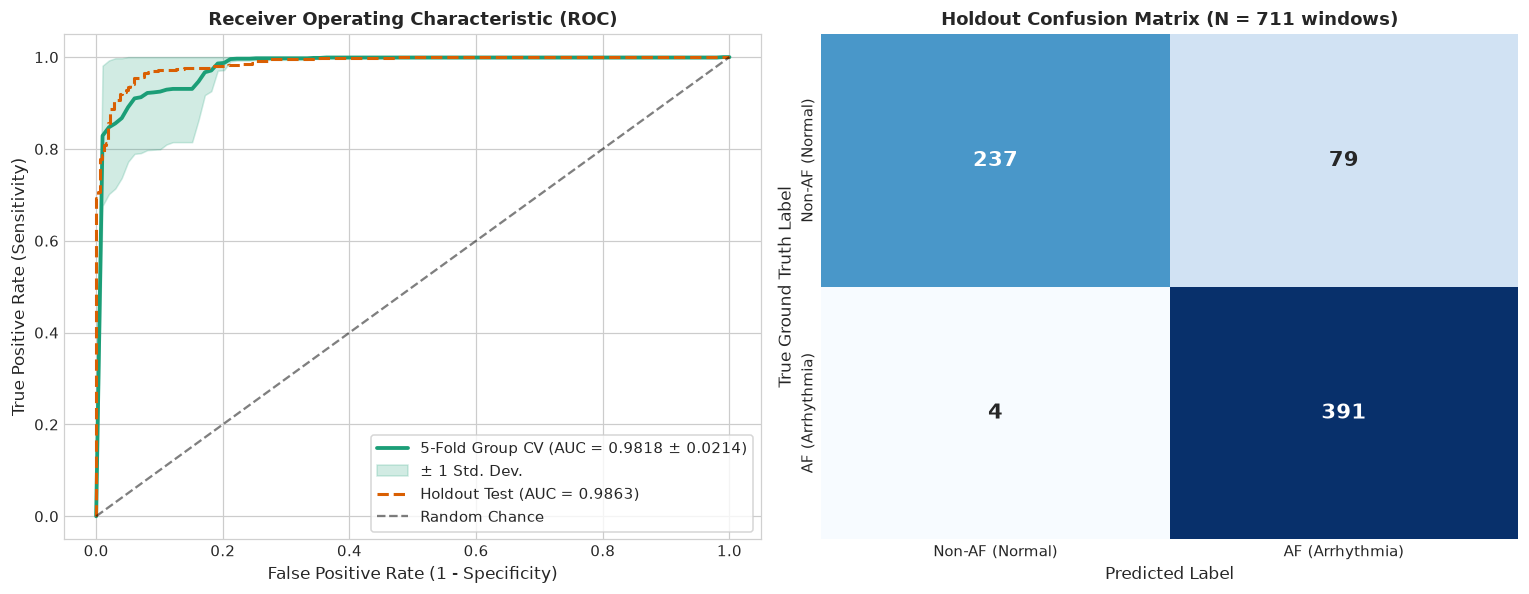

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Plot 1: ROC Curves
mean_fpr = np.linspace(0, 1, 100)
cv_tprs = []
cv_aucs = []

for fold, (t_idx, v_idx) in enumerate(sgkf.split(X_train_cv, y_train_cv, groups=groups_train_cv)):
    m = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.05, num_leaves=31, max_depth=6,
                           subsample=0.8, colsample_bytree=0.8, random_state=42 + fold, verbose=-1)
    m.fit(X_train_cv[t_idx], y_train_cv[t_idx])
    prb = m.predict_proba(X_train_cv[v_idx])[:, 1]
    fpr_f, tpr_f, _ = roc_curve(y_train_cv[v_idx], prb)
    cv_tprs.append(np.interp(mean_fpr, fpr_f, tpr_f))
    cv_tprs[-1][0] = 0.0
    cv_aucs.append(roc_auc_score(y_train_cv[v_idx], prb))

mean_tpr = np.mean(cv_tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = np.mean(cv_aucs)
std_auc = np.std(cv_aucs)

axes[0].plot(mean_fpr, mean_tpr, color='#1b9e77', lw=2.5, label=f'5-Fold Group CV (AUC = {mean_auc:.4f} ± {std_auc:.4f})')
std_tpr = np.std(cv_tprs, axis=0)
axes[0].fill_between(mean_fpr, np.maximum(mean_tpr - std_tpr, 0), np.minimum(mean_tpr + std_tpr, 1),
                     color='#1b9e77', alpha=0.2, label='± 1 Std. Dev.')

fpr_h, tpr_h, _ = roc_curve(y_test_holdout, holdout_probs)
axes[0].plot(fpr_h, tpr_h, color='#d95f02', lw=2, linestyle='--', label=f'Holdout Test (AUC = {roc_auc_score(y_test_holdout, holdout_probs):.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance')
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[0].set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
axes[0].set_title("Receiver Operating Characteristic (ROC)", fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True)

# Plot 2: Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Non-AF (Normal)', 'AF (Arrhythmia)'],
            yticklabels=['Non-AF (Normal)', 'AF (Arrhythmia)'],
            cbar=False, annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_xlabel("Predicted Label", fontsize=11)
axes[1].set_ylabel("True Ground Truth Label", fontsize=11)
axes[1].set_title(f"Holdout Confusion Matrix (N = {len(y_test_holdout)} windows)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


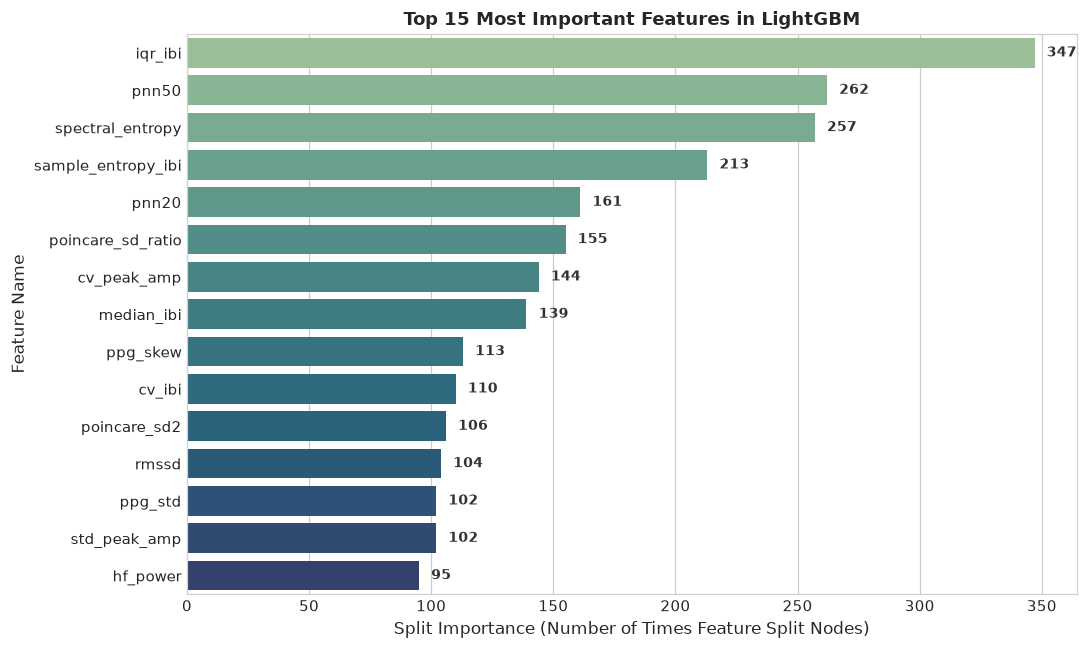

In [14]:
# Feature Importance Plot
top_feats = pd.Series(final_lgbm.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_feats.values, y=top_feats.index, palette='crest', ax=ax)
ax.set_title("Top 15 Most Important Features in LightGBM", fontsize=12, fontweight='bold')
ax.set_xlabel("Split Importance (Number of Times Feature Split Nodes)", fontsize=11)
ax.set_ylabel("Feature Name", fontsize=11)

# Annotate feature importance values
for idx, (name, val) in enumerate(top_feats.items()):
    ax.text(val + 5, idx, f"{val}", va='center', fontsize=9, fontweight='bold', color='#333333')

plt.tight_layout()
plt.show()

## 11. Results Analysis & Key Findings

### Top Predictive Features
1. **Pulse Rate Variability (`iqr_ibi`, `pnn50`, `pnn20`, `rmssd`):**  
   Interval irregularity is the strongest indicator of arrhythmia. The top features in LightGBM are `iqr_ibi` (interquartile range of intervals) and `pnn50` (percentage of consecutive intervals differing by > 50 ms), reflecting the erratic ventricular rhythm of AF.
2. **Entropy & Rhythm Complexity (`spectral_entropy`, `sample_entropy_ibi`):**  
   Arrhythmic episodes create chaotic, non-repeating pulse trains that significantly increase Sample Entropy and flatten the power spectral distribution.
3. **Pulse Amplitude Variations (`cv_peak_amp`):**  
   Varying cardiac filling times cause beat-to-beat changes in stroke volume, creating observable pulse height variations that provide valuable predictive signal.

### Test Set Observations
- In the holdout test set, one non-AF patient (`mimic_perform_non_af_014`) was classified with high arrhythmia probability due to frequent premature beats and low signal amplitude on short 30-second segments.
- Aggregating predictions over multiple consecutive windows (e.g., 2–5 minutes) or using majority voting effectively filters out single-window anomalies for reliable patient-level decisions.

### Potential Future Improvements
- **Motion Artifact Handling:** Incorporate 3-axis accelerometer signals for active noise filtering during physical movement.
- **Multi-Class Arrhythmia Classification:** Expand beyond binary classification to differentiate between other arrhythmias such as premature contractions (PACs/PVCs) and tachycardia.
- **Edge Deployment:** Export the model to ONNX or TensorFlow Lite for lightweight on-device inference on smartwatches or mobile applications.